# FraudShield - Part A: Data understanding and preprocessing


In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42

print("Python environment:", sys.executable)
print("Working folder:", Path.cwd())
print("All imports successful!")

Python environment: C:\Projects\FraudShield\.venv\Scripts\python.exe
Working folder: C:\projects\FraudShield
All imports successful!


In [3]:
data_path = Path("data") / "creditcard.csv"
df = pd.read_csv(data_path)
print ("Dataset dimensions: ", df.shape)
display(df.head())
print(f"Number of transactions: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Number of input features: {df.shape[1] - 1}")
df.info()

Dataset dimensions:  (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Number of transactions: 284,807
Number of columns: 31
Number of input features: 30
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807

In [4]:
missing_values = df.isna().sum()

display(
    missing_values.to_frame("missing values")
)

print("Total missing values:", missing_values.sum())

,missing values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total missing values: 0


In [5]:
duplicate_mask = df.duplicated()

print ("Number of duplicate rows:", duplicate_mask.sum())

duplicate_counts = (
    df.loc[duplicate_mask,  "Class"]
    .value_counts()
    .reindex([0,1], fill_value =0)
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

display(duplicate_counts.to_frame("Duplicate copies"))

#show examples, including their original occurences
display(df[df.duplicated(keep=False)].head(10))


Number of duplicate rows: 1081


,Duplicate copies
Class,
Legitimate,1062
Fraudulent,19


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [6]:
df_clean = df.drop_duplicates().copy()

print("Original number of rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

print("\nRemaining transactions by class:")
display(df_clean["Class"].value_counts().sort_index())


Original number of rows: 284807
Rows after removing duplicates: 283726
Rows removed: 1081
Remaining duplicates: 0

Remaining transactions by class:


Class
0    283253
1       473
Name: count, dtype: int64

In [7]:
print("Class labels:", df_clean["Class"].unique())
print("Missing values:", df_clean.isna().sum().sum())
print("Infinite values:", np.isinf(df_clean.select_dtypes(include="number")).sum().sum())
print("Negative amounts:", (df_clean["Amount"] < 0).sum())
print("Negative times:", (df_clean["Time"] < 0).sum())
print("Remaining duplicate copies:", df_clean.duplicated().sum())

assert set(df_clean["Class"].unique()) == {0, 1}, "Investigate unexpected labels."
assert df_clean.isna().sum().sum() == 0, "Investigate missing values."
assert np.isfinite(df_clean.to_numpy()).all(), "Investigate non-finite values."
assert (df_clean["Amount"] >= 0).all(), "Investigate negative amounts."
assert (df_clean["Time"] >= 0).all(), "Investigate negative times."
assert not df_clean.duplicated().any(), "Exact duplicate rows remain."
print("Basic data-quality checks passed.")


Class labels: [0 1]
Missing values: 0
Infinite values: 0
Negative amounts: 0
Negative times: 0
Remaining duplicate copies: 0
Basic data-quality checks passed.


,Count,Percentage
Legitimate,283253,99.8333
Fraudulent,473,0.1667


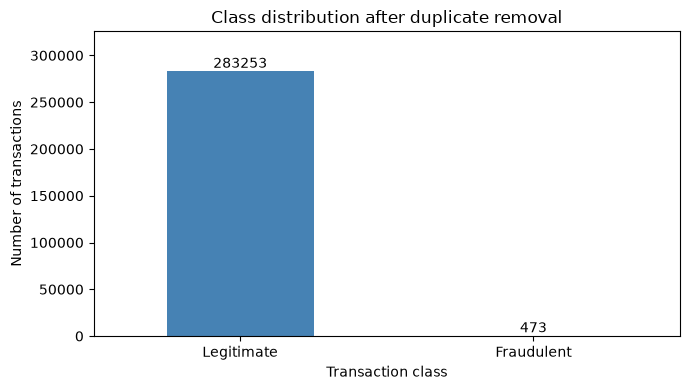

In [8]:
class_counts = df_clean["Class"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / len(df_clean) * 100
})

class_summary.index = ["Legitimate", "Fraudulent"]

display(class_summary.round(4))

ax = class_summary["Count"].plot(
    kind="bar",
    color=["steelblue", "firebrick"],
    figsize=(7, 4),
    rot=0
)

ax.set_title("Class distribution after duplicate removal")
ax.set_xlabel("Transaction class")
ax.set_ylabel("Number of transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold

RANDOM_STATE = 42

# Input features: every column except the answer
X = df_clean.drop(columns="Class")

# Target: the answer we want to predict
y = df_clean["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Cross-validation for later model development
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

split_summary = pd.DataFrame({
    "Transactions": [len(y_train), len(y_test)],
    "Fraud cases": [y_train.sum(), y_test.sum()],
    "Fraud percentage": [
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
}, index=["Training", "Test"])

display(split_summary.round(4))

# Confirm that no original row belongs to both sets
assert X_train.index.intersection(X_test.index).empty
assert "Class" not in X_train.columns

Training features: (226980, 30)
Test features: (56746, 30)


,Transactions,Fraud cases,Fraud percentage
Training,226980,378,0.1665
Test,56746,95,0.1674


In [10]:
# These checks compare identifiers/features, not model performance on the test set.
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert len(X_train) + len(X_test) == len(df_clean)

# Removing full-row duplicates would not catch identical inputs with different labels.
# Check inputs alone before using ordinary stratified folds.
feature_duplicate_count = int(X.duplicated().sum())
print("Extra identical-feature rows after cleaning:", feature_duplicate_count)
assert feature_duplicate_count == 0, (
    "Identical inputs remain. Inspect conflicting labels and use group-aware splits "
    "before continuing; do not silently drop the conflicting rows."
)

# Materialize one fixed set of folds for fair comparisons in Part B.
cv_splits = list(cv.split(X_train, y_train))
fold_rows = []
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    assert np.intersect1d(fit_idx, valid_idx).size == 0
    assert len(fit_idx) + len(valid_idx) == len(X_train)
    assert y_train.iloc[fit_idx].nunique() == 2
    assert y_train.iloc[valid_idx].nunique() == 2
    fold_rows.append({
        "Fold": fold,
        "Fit rows": len(fit_idx),
        "Validation rows": len(valid_idx),
        "Fit fraud cases": int(y_train.iloc[fit_idx].sum()),
        "Validation fraud cases": int(y_train.iloc[valid_idx].sum())
    })

# Every development row must be validated exactly once.
validation_positions = np.concatenate([valid_idx for _, valid_idx in cv_splits])
assert np.array_equal(np.sort(validation_positions), np.arange(len(X_train)))
display(pd.DataFrame(fold_rows).set_index("Fold"))
print("Split and fold checks passed. Keep X_test/y_test for final evaluation.")


Extra identical-feature rows after cleaning: 0


,Fit rows,Validation rows,Fit fraud cases,Validation fraud cases
Fold,,,,
1,181584,45396,303,75
2,181584,45396,303,75
3,181584,45396,302,76
4,181584,45396,302,76
5,181584,45396,302,76


Split and fold checks passed. Keep X_test/y_test for final evaluation.


In [11]:
feature_summary = X_train.describe().T

feature_summary["range"] = (
    feature_summary["max"] - feature_summary["min"]
)

display(
    feature_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max", "range"]
    ].round(3)
)

,mean,std,min,25%,50%,75%,max,range
Time,94900.224,47488.214,0.000,54241.750,84816.000,139364.250,172792.000,172792.000
V1,0.005,1.947,-56.408,-0.916,0.018,1.315,2.455,58.862
V2,-0.006,1.650,-72.716,-0.601,0.064,0.801,22.058,94.773
V3,0.002,1.507,-33.681,-0.887,0.178,1.027,9.383,43.064
V4,-0.002,1.417,-5.683,-0.849,-0.022,0.741,16.875,22.559
V5,0.005,1.360,-32.092,-0.689,-0.052,0.615,34.802,66.894
V6,-0.002,1.323,-26.161,-0.769,-0.276,0.397,21.393,47.554
V7,0.001,1.200,-43.557,-0.552,0.041,0.572,34.303,77.860
V8,-0.000,1.169,-73.217,-0.209,0.022,0.325,20.007,93.224
V9,-0.003,1.094,-13.434,-0.644,-0.053,0.594,15.595,29.029


Constant input features: []


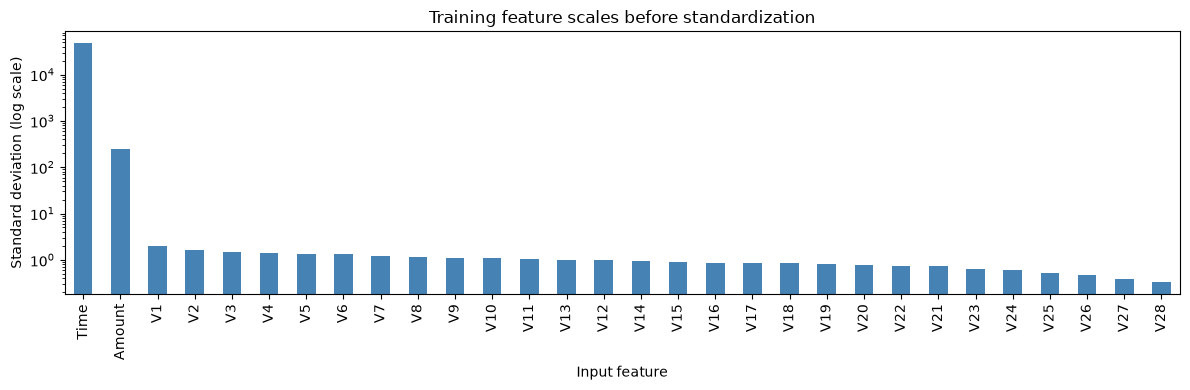

,mean,median,std,min,max
Time,94900.224,84816.00,47488.214,0.0,172792.00
Amount,88.387,22.08,245.767,0.0,19656.53


In [12]:
constant_features = X_train.columns[X_train.nunique() <= 1].tolist()
print("Constant input features:", constant_features)

# The logarithmic axis makes large differences in standard deviation readable.
std_by_feature = X_train.std().sort_values(ascending=False)
ax = std_by_feature[std_by_feature > 0].plot.bar(
    figsize=(12, 4), color="steelblue", logy=True
)
ax.set_title("Training feature scales before standardization")
ax.set_xlabel("Input feature")
ax.set_ylabel("Standard deviation (log scale)")
plt.tight_layout()
plt.show()

display(X_train[["Time", "Amount"]].agg(["mean", "median", "std", "min", "max"]).T.round(3))


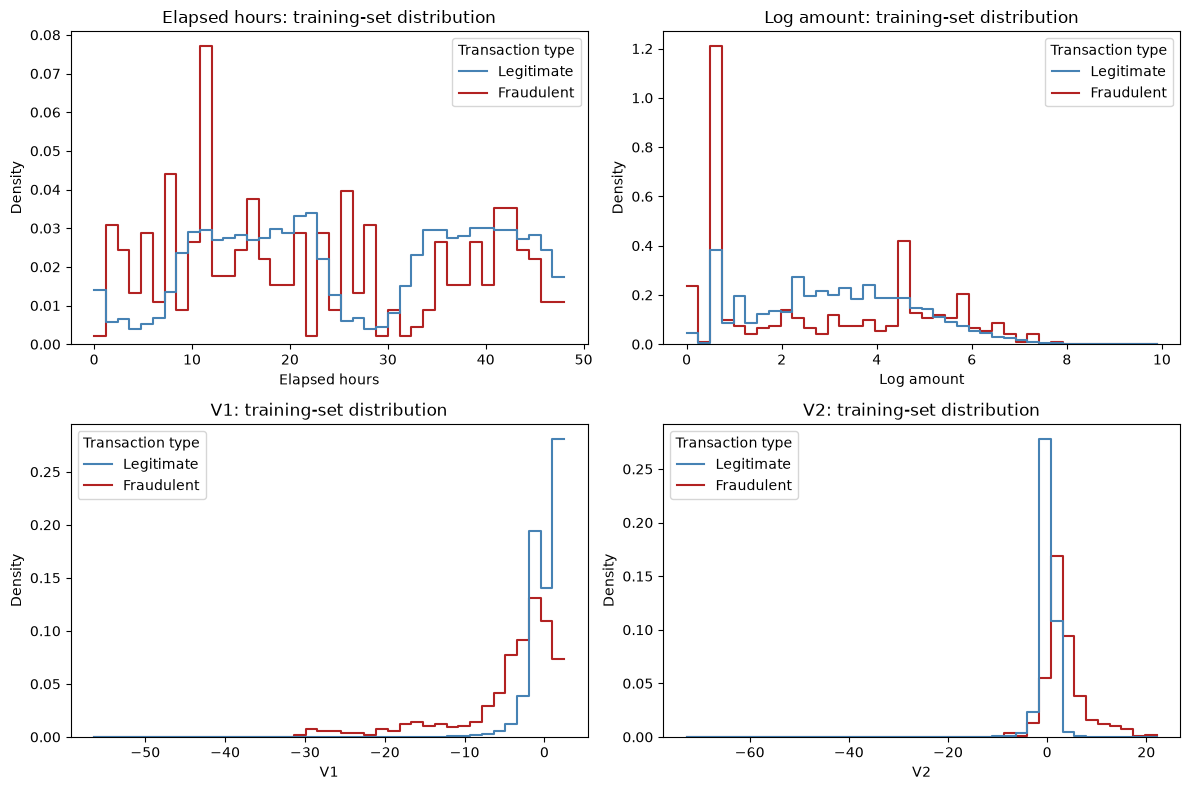

In [13]:
# A separate table used only for exploration
train_eda = X_train.copy()

train_eda["Transaction type"] = y_train.map({
    0: "Legitimate",
    1: "Fraudulent"
})

# These columns are for plotting only
train_eda["Elapsed hours"] = train_eda["Time"] / 3600
train_eda["Log amount"] = np.log1p(train_eda["Amount"])

plot_columns = ["Elapsed hours", "Log amount", "V1", "V2"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(plot_columns, axes.flat):
    sns.histplot(
        data=train_eda,
        x=column,
        hue="Transaction type",
        hue_order=["Legitimate", "Fraudulent"],
        palette={"Legitimate": "steelblue", "Fraudulent": "firebrick"},
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=ax
    )

    ax.set_title(f"{column}: training-set distribution")

plt.tight_layout()
plt.show()


In [14]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def build_model_pipeline(model, scale=True):
    """Return an unfitted, independent model pipeline for training/CV."""
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", clone(model)))
    return Pipeline(steps)


In [15]:
fit_idx, valid_idx = cv_splits[0]
fold_fit = X_train.iloc[fit_idx]
fold_valid = X_train.iloc[valid_idx]

demo_scaler = StandardScaler()
demo_fit_scaled = demo_scaler.fit_transform(fold_fit)
demo_valid_scaled = demo_scaler.transform(fold_valid)

nonconstant = fold_fit.var(ddof=0).to_numpy() > 0
assert np.isfinite(demo_fit_scaled).all()
assert np.isfinite(demo_valid_scaled).all()
assert np.allclose(demo_fit_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(demo_fit_scaled.std(axis=0, ddof=0)[nonconstant], 1, atol=1e-10)

scale_check = pd.DataFrame({
    "Fit mean before": fold_fit.mean(),
    "Fit std before": fold_fit.std(ddof=0),
    "Fit mean after": demo_fit_scaled.mean(axis=0),
    "Fit std after": demo_fit_scaled.std(axis=0, ddof=0),
    "Validation mean after": demo_valid_scaled.mean(axis=0)
}, index=X_train.columns)
display(scale_check.loc[["Time", "Amount", "V1", "V2"]].round(4))
print("Scaling checks passed. Validation data used transform only.")

# Avoid accidentally reusing demonstration arrays in later model selection.
del demo_scaler, demo_fit_scaled, demo_valid_scaled, fold_fit, fold_valid


,Fit mean before,Fit std before,Fit mean after,Fit std after,Validation mean after
Time,94889.4008,47488.0788,0.0,1.0,0.0011
Amount,87.9121,241.7520,0.0,1.0,0.0098
V1,0.0034,1.9481,0.0,1.0,0.0043
V2,-0.0029,1.6386,0.0,1.0,-0.0082


Scaling checks passed. Validation data used transform only.


# FraudShield - Part B: Baseline models

**Goal:** train Logistic Regression (transparent baseline) and four additional models, tune each one, and compare them **on exactly the same five training folds (`cv_splits`) from Part A**. The test set (`X_test`, `y_test`) is **not touched** here; it is reserved for the final evaluation in Part C.

| Model | Family | Why it is included |
|---|---|---|
| Logistic Regression | Linear | Required, transparent baseline; coefficients are directly interpretable |
| Decision Tree | Tree | Required tree-based model; human-readable rules |
| Random Forest | Tree ensemble (bagging) | Reduces the variance of a single tree; strong on tabular data |
| Histogram Gradient Boosting | Tree ensemble (boosting) | Builds trees sequentially to correct earlier errors; fast on 200k+ rows |
| k-Nearest Neighbours | Distance-based | A completely different inductive bias (local similarity); shows why scaling matters |

**Model-selection metric: average precision (area under the precision-recall curve, PR-AUC).** With 0.17 % fraud, a model that predicts "legitimate" for every transaction is 99.83 % accurate, so accuracy is meaningless. ROC-AUC is also optimistic here because the false-positive *rate* stays tiny even when false alarms outnumber the frauds caught. PR-AUC only looks at how well the fraud cases are ranked against false alarms, and it does not depend on any one threshold. We also record ROC-AUC, and precision, recall, and F1 at the default 0.5 threshold. Choosing a better threshold belongs to Parts C/D.

**Leakage control:** every model sits inside `build_model_pipeline`, so `StandardScaler` is refitted on each training fold only. Training-fold scores (`return_train_score=True`) are kept so we can detect overfitting.

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, precision_recall_curve
)

# One scoring dictionary shared by every model, so all comparisons use the same metrics.
# zero_division=0: a fold where a model flags nothing gets precision 0 instead of a warning.
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score),
    "f1": make_scorer(f1_score),
}

N_JOBS = -1  # parallelism is at the grid-search level; the models themselves use 1 core

### Parameter choices

Each grid is small on purpose and only covers the settings that should matter most for **this** problem. These are not default-only models: each grid includes class weighting (`None` versus `balanced`), and each one includes the setting that controls how complex the model can get.

- **Logistic Regression:** `C` is the inverse regularisation strength, searched across four orders of magnitude. `class_weight="balanced"` weights each fraud case about 300 times more than a legitimate one in the loss. `max_iter` is raised so the solver converges on scaled data.
- **Decision Tree:** `max_depth` and `min_samples_leaf` limit how far the tree can grow. An unlimited tree would memorise the 300 fraud cases in each training fold.
- **Random Forest:** a single 150-tree forest on about 180k rows took about 4.5 minutes on one core, which is too slow for a grid search. Each tree is therefore grown on a 30 % bootstrap sample (`max_samples=0.3`). This is still several thousand rows per tree, and it makes the trees less alike, which is the point of bagging. `min_samples_leaf` and `balanced_subsample` weighting are tuned.
- **Histogram Gradient Boosting:** the learning rate and `max_leaf_nodes` (tree size) are tuned. The number of boosting rounds is set by **early stopping** on a 10 % validation split taken from *inside* each training fold, so no CV-validation data is used to pick it.
- **k-NN:** `n_neighbors` is tuned. With only about 300 fraud cases per fold, a large *k* can drown out the fraud neighbours, so the grid goes up to 35. Distance weighting gives closer neighbours more say. k-NN has no `class_weight` option.

In [ ]:
model_specs = {
    "Logistic Regression": dict(
        model=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        scale=True,
        grid={"model__C": [0.01, 0.1, 1, 10],
              "model__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": dict(
        model=DecisionTreeClassifier(random_state=RANDOM_STATE),
        scale=False,  # trees split on thresholds, so feature scale is irrelevant
        grid={"model__max_depth": [4, 8, 12],
              "model__min_samples_leaf": [1, 20],
              "model__class_weight": [None, "balanced"]},
    ),
    "Random Forest": dict(
        model=RandomForestClassifier(n_estimators=100, max_samples=0.3, max_features="sqrt",
                                     n_jobs=1, random_state=RANDOM_STATE),
        scale=False,
        grid={"model__min_samples_leaf": [1, 5],
              "model__class_weight": [None, "balanced_subsample"]},
    ),
    "Gradient Boosting": dict(
        model=HistGradientBoostingClassifier(max_iter=500, early_stopping=True,
                                             validation_fraction=0.1, n_iter_no_change=20,
                                             l2_regularization=1.0, random_state=RANDOM_STATE),
        scale=False,
        grid={"model__learning_rate": [0.05, 0.1],
              "model__max_leaf_nodes": [15, 31],
              "model__class_weight": [None, "balanced"]},
    ),
    "k-NN": dict(
        model=KNeighborsClassifier(weights="distance", n_jobs=1),
        scale=True,  # distances are meaningless without scaling (Amount would dominate)
        grid={"model__n_neighbors": [5, 15, 35]},
    ),
}

for name, spec in model_specs.items():
    n_combos = int(np.prod([len(v) for v in spec["grid"].values()]))
    print(f"{name:<20} {n_combos:>2} settings x {len(cv_splits)} folds = {n_combos * len(cv_splits)} fits")

### Grid search on the shared folds

`cv=cv_splits` passes the **same five folds from Part A** to every search. That is what makes the comparison fair: every model is trained and validated on exactly the same rows. This cell is the slow one (around 10 minutes on 4 cores, mostly the Random Forest).

In [ ]:
searches = {}
for name, spec in model_specs.items():
    start = time.perf_counter()
    search = GridSearchCV(
        estimator=build_model_pipeline(spec["model"], scale=spec["scale"]),
        param_grid=spec["grid"],
        scoring=scoring,
        refit="pr_auc",         # best setting = highest mean validation PR-AUC
        cv=cv_splits,
        return_train_score=True,
        n_jobs=N_JOBS,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:<20} best CV PR-AUC = {search.best_score_:.4f}  "
          f"({time.perf_counter() - start:.0f}s)  {best_params}")

### What each parameter did

The full grid for each model, sorted by validation PR-AUC. The **train − validation gap** shows overfitting: a large gap means the model memorises its training folds.

In [ ]:
def grid_table(search):
    res = pd.DataFrame(search.cv_results_)
    params = res["params"].apply(lambda p: ", ".join(f"{k.replace('model__', '')}={v}" for k, v in p.items()))
    table = pd.DataFrame({
        "Setting": params,
        "Val PR-AUC": res["mean_test_pr_auc"],
        "Val PR-AUC std": res["std_test_pr_auc"],
        "Train PR-AUC": res["mean_train_pr_auc"],
        "Val recall@0.5": res["mean_test_recall"],
        "Val precision@0.5": res["mean_test_precision"],
    })
    table["Train - Val gap"] = table["Train PR-AUC"] - table["Val PR-AUC"]
    return table.sort_values("Val PR-AUC", ascending=False).reset_index(drop=True)

for name, search in searches.items():
    print(name)
    display(grid_table(search).round(4))

### Comparison of the tuned models (5-fold CV, mean ± std)

In [ ]:
summary_rows = []
for name, search in searches.items():
    res = search.cv_results_
    i = search.best_index_
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric} mean"] = res[f"mean_test_{metric}"][i]
        row[f"{metric} std"] = res[f"std_test_{metric}"][i]
    row["train pr_auc"] = res["mean_train_pr_auc"][i]
    row["fit time (s/fold)"] = res["mean_fit_time"][i]
    summary_rows.append(row)

cv_summary = (pd.DataFrame(summary_rows).set_index("Model")
              .sort_values("pr_auc mean", ascending=False))
cv_summary["overfit gap"] = cv_summary["train pr_auc"] - cv_summary["pr_auc mean"]

# Fraud prevalence = PR-AUC of a model that guesses at random; every model must beat this.
print(f"Random-guess PR-AUC (fraud rate in training data): {y_train.mean():.4f}")
display(cv_summary.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
order = cv_summary.index[::-1]
ax.barh(order, cv_summary.loc[order, "pr_auc mean"], xerr=cv_summary.loc[order, "pr_auc std"],
        color="steelblue", capsize=4)
ax.set_xlabel("Validation PR-AUC (mean ± std over 5 folds)")
ax.set_title("Tuned models on identical CV folds")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

### Out-of-fold predictions

For every training row we collect the predicted fraud probability from the one model that **did not** see that row during fitting (same `cv_splits`). These out-of-fold (OOF) scores cover all 378 training frauds, which gives smoother PR curves than a single fold. They are also what we will use in Parts C/D to choose thresholds **without touching the test set**.

In [ ]:
best_pipelines = {name: s.best_estimator_ for name, s in searches.items()}  # refit on all of X_train

oof_proba = {}
for name, search in searches.items():
    oof_proba[name] = cross_val_predict(
        clone(search.best_estimator_), X_train, y_train,
        cv=cv_splits, method="predict_proba", n_jobs=N_JOBS
    )[:, 1]
oof_proba = pd.DataFrame(oof_proba, index=X_train.index)

fig, ax = plt.subplots(figsize=(7, 6))
for name in cv_summary.index:
    precision, recall, _ = precision_recall_curve(y_train, oof_proba[name])
    ap = average_precision_score(y_train, oof_proba[name])
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label="Random guess")
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Out-of-fold precision-recall curves (training data)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

# Operating points at the default threshold, pooled over folds
rows = []
for name in cv_summary.index:
    pred = (oof_proba[name] >= 0.5).astype(int)
    tp = int(((pred == 1) & (y_train == 1)).sum())
    fp = int(((pred == 1) & (y_train == 0)).sum())
    fn = int(((pred == 0) & (y_train == 1)).sum())
    rows.append({"Model": name, "Frauds caught (TP)": tp, "Frauds missed (FN)": fn,
                 "False alarms (FP)": fp, "Recall": tp / (tp + fn),
                 "Precision": tp / (tp + fp) if tp + fp else 0.0})
display(pd.DataFrame(rows).set_index("Model").round(3))

### Part B observations

*(Fill in after running; the numbers in the cells above are the source of truth.)*

- Which model ranks frauds best (PR-AUC), and is its lead larger than the fold-to-fold standard deviation?
- Did `class_weight="balanced"` help or hurt PR-AUC? Look at what it does to recall versus precision at 0.5: weighting moves the predicted probabilities up, so a fixed 0.5 cut-off tells you little about ranking quality.
- Which models overfit (large train − validation gap), and did limiting their complexity help?
- Speed and interpretability compared with accuracy: is a more complex model worth it compared with Logistic Regression?